<a href="https://colab.research.google.com/github/katiyardivyanshu08-bit/Retail_Pulse_Project_/blob/main/1_Retail_data_clean.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
# Statistical visualization
import matplotlib.pyplot as plt
# Ignore warnings
import warnings
warnings.filterwarnings('ignore')
# Getting access
# from google.colab import drive
# drive.mount('/content/drive')

In [2]:
url = "https://raw.githubusercontent.com/katiyardivyanshu08-bit/Retail_Pulse_Project_/main/Data/RetailPulse_500000_rows.csv"
df = pd.read_csv(url)
df.shape #(801600, 13)
df.head(10)
df.tail()
df.sample(10)

,CustomerID,Age,Gender,Region,ProductCategory,AnnualIncome,PurchaseFrequency,AnnualPurchaseAmount,LastPurchaseDate,CustomerTenure,DiscountUsage,ReturnRate,CustomerSegment
338617,428669,35,Other,Central,Grocery,70118.81,8.0,12002.64,2025-09-30,4.55,0.0483,0.0667,Regular
112087,338476,35,Female,North,Beauty,39108.71,9.0,11567.10,2025-12-30,5.75,0.0982,0.0778,Regular
355743,367834,34,Male,North,Home & Kitchen,77240.76,2.0,7867.13,2025-11-03,4.33,0.0967,0.0575,Regular
211473,122933,50,Male,SOUTH,Clothing,52366.02,8.0,13966.50,2025-11-22,1.45,0.3177,0.0735,Regular
201663,581445,50,Female,West,Clothing,36369.80,8.0,6215.28,2025-11-13,4.44,0.2477,0.0534,Regular
499057,488044,65,Male,Central,Sports,33771.58,7.0,9749.44,2025-11-23,3.04,0.3116,0.0393,Regular
123723,472062,18,Male,West,Beauty,39759.82,8.0,4897.90,2025-10-20,2.46,0.3092,0.0523,Budget
381483,360697,38,Female,South,Sports,26630.09,3.0,4105.00,2025-10-24,9.97,0.5098,0.1349,Regular
165837,525786,40,Female,Central,Sports,74110.60,14.0,16301.49,2025-12-30,7.51,0.5020,0.0683,Premium
375044,134105,39,Female,Central,NaN,40653.18,4.0,8836.29,2025-11-21,1.54,0.0934,0.0711,Budget


In [3]:
df["LastPurchaseDate"] = pd.to_datetime(
    df["LastPurchaseDate"],
    format="mixed",
    dayfirst=True,
    errors="coerce"
)

In [4]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 500000 entries, 0 to 499999
Data columns (total 13 columns):
 #   Column                Non-Null Count   Dtype         
---  ------                --------------   -----         
 0   CustomerID            500000 non-null  int64         
 1   Age                   500000 non-null  int64         
 2   Gender                497001 non-null  str           
 3   Region                496504 non-null  str           
 4   ProductCategory       497001 non-null  str           
 5   AnnualIncome          495002 non-null  float64       
 6   PurchaseFrequency     495998 non-null  float64       
 7   AnnualPurchaseAmount  500000 non-null  float64       
 8   LastPurchaseDate      500000 non-null  datetime64[us]
 9   CustomerTenure        500000 non-null  float64       
 10  DiscountUsage         494997 non-null  float64       
 11  ReturnRate            496500 non-null  float64       
 12  CustomerSegment       500000 non-null  str           
dtypes: datetim

In [5]:
df.describe()

,CustomerID,Age,AnnualIncome,PurchaseFrequency,AnnualPurchaseAmount,LastPurchaseDate,CustomerTenure,DiscountUsage,ReturnRate
count,500000.000000,500000.000000,495002.000000,495998.000000,500000.000000,500000,500000.000000,494997.000000,496500.000000
mean,349499.546422,40.856144,67404.824695,8.596408,12884.542060,2025-09-22 22:31:25.190400,4.243120,0.339433,0.085718
min,100001.000000,18.000000,18000.000000,1.000000,565.000000,2024-12-31 00:00:00,0.250000,0.005100,0.000000
25%,224736.750000,32.000000,43434.195000,5.000000,6763.360000,2025-08-07 00:00:00,2.270000,0.187200,0.049700
50%,349483.500000,40.000000,60097.425000,7.000000,10392.100000,2025-10-30 00:00:00,3.700000,0.309500,0.075800
75%,474260.250000,49.000000,83034.477500,11.000000,16047.522500,2025-12-12 00:00:00,5.640000,0.466800,0.111600
max,599000.000000,70.000000,350000.000000,55.000000,316973.080000,2025-12-30 00:00:00,14.800000,0.980000,0.524700
std,144051.571449,11.756830,34246.285517,5.554789,9422.420371,NaN,2.646383,0.190285,0.049652


In [6]:
df.columns

Index(['CustomerID', 'Age', 'Gender', 'Region', 'ProductCategory',
       'AnnualIncome', 'PurchaseFrequency', 'AnnualPurchaseAmount',
       'LastPurchaseDate', 'CustomerTenure', 'DiscountUsage', 'ReturnRate',
       'CustomerSegment'],
      dtype='str')

In [7]:
num=df.select_dtypes(include="number").columns
cat=df.select_dtypes(include="object").columns
print(num)
print(cat)

Index(['CustomerID', 'Age', 'AnnualIncome', 'PurchaseFrequency',
       'AnnualPurchaseAmount', 'CustomerTenure', 'DiscountUsage',
       'ReturnRate'],
      dtype='str')
Index(['Gender', 'Region', 'ProductCategory', 'CustomerSegment'], dtype='str')


**Numerical Column**

In [8]:
# df.isnull().mean()*100
df.select_dtypes(include="number").isnull().sum()

CustomerID                 0
Age                        0
AnnualIncome            4998
PurchaseFrequency       4002
AnnualPurchaseAmount       0
CustomerTenure             0
DiscountUsage           5003
ReturnRate              3500
dtype: int64

In [9]:
null_count=df.select_dtypes(include=["number"]).isnull().sum()
null_count[null_count>0]

AnnualIncome         4998
PurchaseFrequency    4002
DiscountUsage        5003
ReturnRate           3500
dtype: int64

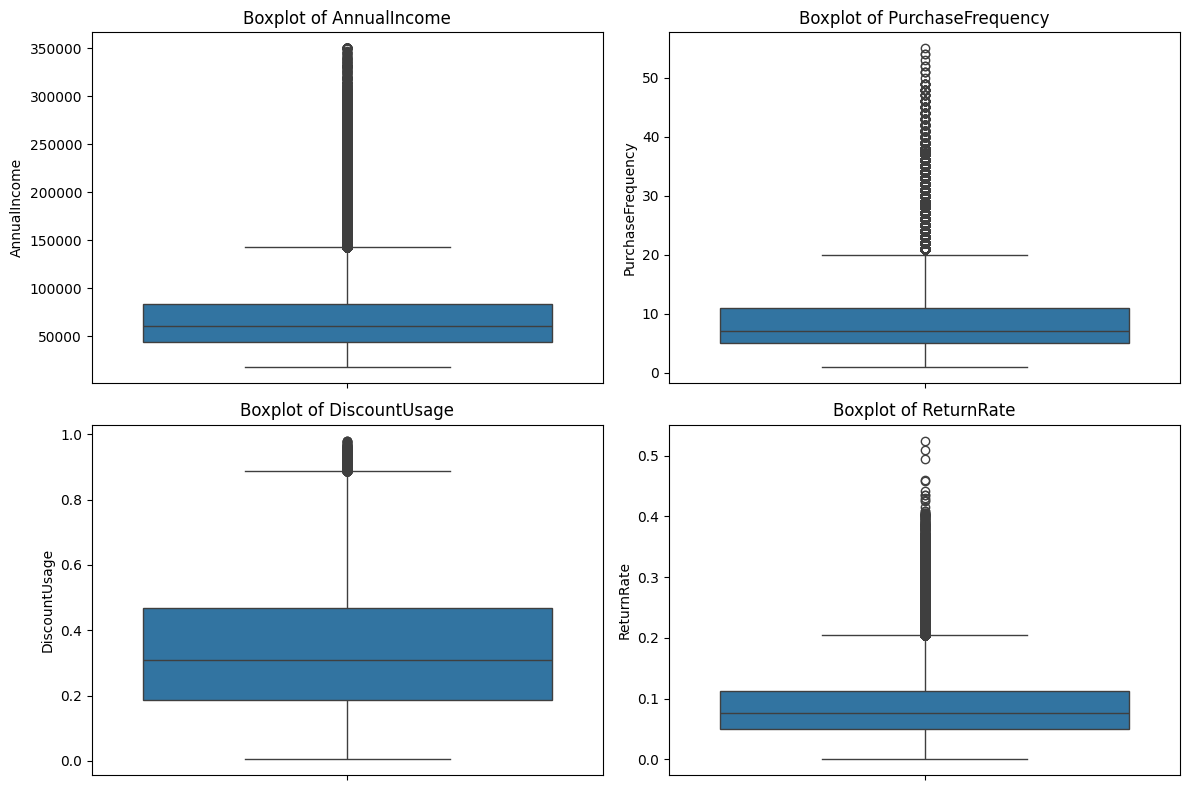

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

num_cols = [
    "AnnualIncome",
    "PurchaseFrequency",
    "DiscountUsage",
    "ReturnRate"
]

plt.figure(figsize=(12, 8))

for i, col in enumerate(num_cols, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(y=df[col])
    plt.title(f"Boxplot of {col}")

plt.tight_layout()
plt.show()

In [11]:
num_cols = [
    "AnnualIncome",
    "PurchaseFrequency",
    "DiscountUsage",
    "ReturnRate"
]

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

**Categorical**

In [12]:
cat

Index(['Gender', 'Region', 'ProductCategory', 'CustomerSegment'], dtype='str')

In [13]:
df.select_dtypes(include="object").isnull().sum()

Gender             2999
Region             3496
ProductCategory    2999
CustomerSegment       0
dtype: int64

In [14]:
null_count=df.select_dtypes(include=["object"]).isnull().sum()
null_count[null_count>0]

Gender             2999
Region             3496
ProductCategory    2999
dtype: int64

In [15]:
df["Gender"].unique()

<StringArray>
['Male', 'Female', nan, 'Other']
Length: 4, dtype: str

In [16]:
for col in cat:
    df[col] = df[col].str.strip().str.lower()

In [17]:
df["Gender"] = df["Gender"].replace("other", "unknown")

In [18]:
df["Region"].unique()

<StringArray>
['north', 'east', 'central', 'south', 'west', nan]
Length: 6, dtype: str

In [19]:
df["ProductCategory"].unique()

<StringArray>
[          'beauty',         'clothing',      'electronics',
   'home & kitchen',          'grocery',           'sports',
                nan, 'home and kitchen']
Length: 8, dtype: str

In [20]:
df["ProductCategory"] = df["ProductCategory"].replace({
    "home and kitchen": "home & kitchen"
})

In [21]:
df["CustomerSegment"].unique()

<StringArray>
['regular', 'budget', 'premium']
Length: 3, dtype: str

In [22]:
for col in cat:
    df[col] = df[col].fillna("unknown")

**Add new with existing feature**

In [23]:
df["LastPurchaseDate"].dtype

dtype('<M8[us]')

In [24]:
reference_date = pd.Timestamp("2025-12-31")
df["Recency"] = (
    reference_date - df["LastPurchaseDate"]
).dt.days
df.drop("LastPurchaseDate", axis=1, inplace=True)

In [25]:
df["Recency"].sample(5)

104366    110
126285    365
156841     19
454848     49
364368     10
Name: Recency, dtype: int64

**Duplicate**

In [26]:
# df.duplicated().sum()  #1000
df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)

In [27]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 499000 entries, 0 to 498999
Data columns (total 13 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   CustomerID            499000 non-null  int64  
 1   Age                   499000 non-null  int64  
 2   Gender                499000 non-null  str    
 3   Region                499000 non-null  str    
 4   ProductCategory       499000 non-null  str    
 5   AnnualIncome          499000 non-null  float64
 6   PurchaseFrequency     499000 non-null  float64
 7   AnnualPurchaseAmount  499000 non-null  float64
 8   CustomerTenure        499000 non-null  float64
 9   DiscountUsage         499000 non-null  float64
 10  ReturnRate            499000 non-null  float64
 11  CustomerSegment       499000 non-null  str    
 12  Recency               499000 non-null  int64  
dtypes: float64(6), int64(3), str(4)
memory usage: 49.5 MB


In [28]:
# df.to_csv("After_clean_retailpulse.csv", index=False)